# 11 · Instances, panoptic maps, and point prompts

**Level:** advanced concepts / expert-topic introduction · **Time:** 90–120 minutes
**Runs:** offline, CPU; no neural checkpoints or downloads

**Prerequisites:** binary masks, morphology, watershed, IoU, and a basic understanding of
learned segmentation. All code is self-contained apart from the project bootstrap.

**You will learn to:** separate touching objects with watershed; match object IDs using IoU
and one-to-one assignment; distinguish pixel overlap from object detection; encode semantic
and instance information together; run a point-prompt random-walker experiment.

These are working classical algorithms and a small panoptic evaluation exercise. They introduce
ideas used in advanced systems; they do not implement or train SAM, Mask R-CNN, or a foundation model.


In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "learning" / "data.py").is_file()), None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the complete ImageSegmentationPractical folder.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 3.5), "image.cmap": "gray",
                     "axes.spines.top": False, "axes.spines.right": False})
print("Project:", PROJECT_ROOT.name)


Project: ImageSegmentationPractical


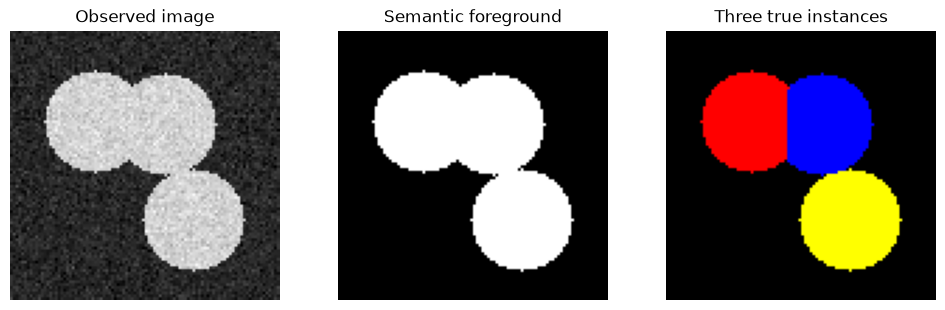

In [2]:
import pandas as pd
from scipy import ndimage as ndi
from scipy.optimize import linear_sum_assignment
from skimage.feature import peak_local_max
from skimage.segmentation import watershed, random_walker, find_boundaries
from skimage.color import label2rgb

rng = np.random.default_rng(25)
height = width = 96
yy, xx = np.mgrid[:height, :width]
centers = np.array([[32, 30], [33, 55], [67, 65]])  # row, column
radius = 18
squared_distances = np.stack([(yy-y)**2+(xx-x)**2 for y, x in centers])
foreground_truth = squared_distances.min(axis=0) <= radius**2
# Overlaps belong to the nearest center, giving non-overlapping visible instance labels.
true_instances = np.where(foreground_truth, squared_distances.argmin(axis=0)+1, 0).astype(np.int32)
gray_image = np.clip(0.15+0.65*foreground_truth+rng.normal(0, 0.055, (height, width)), 0, 1)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, data, title in zip(axes, [gray_image, foreground_truth, label2rgb(true_instances, bg_label=0)],
                          ['Observed image', 'Semantic foreground', 'Three true instances']):
    ax.imshow(data, cmap='gray'); ax.set_title(title); ax.axis('off')
plt.show()


## Step 1 — Semantic versus instance labels

A semantic map answers *what class is this pixel?* All three disks belong to the same class.
An instance map answers *which particular object?* IDs 1, 2, and 3 distinguish the disks;
the integer values themselves have no class meaning. Reassigning IDs does not change the segmentation.

Connected components merges touching objects. Watershed instead starts from markers and
assigns regions according to a topographic surface. We use negative distance to background:
object interiors become basins, and detected distance peaks supply markers.


Connected components: 1 Watershed instances: 3


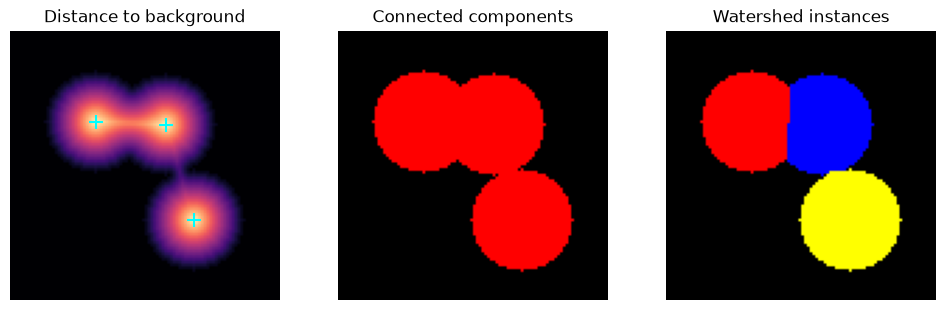

In [3]:
observed_foreground = gray_image > 0.5
connected, n_connected = ndi.label(observed_foreground)
distance = ndi.distance_transform_edt(observed_foreground)

def watershed_instances(foreground, min_distance=12):
    dist = ndi.distance_transform_edt(foreground)
    points = peak_local_max(dist, min_distance=min_distance,
                            labels=foreground.astype(np.uint8), exclude_border=False)
    markers = np.zeros(foreground.shape, np.int32)
    for marker_id, (row, col) in enumerate(points, start=1):
        markers[row, col] = marker_id
    labels = watershed(-dist, markers, mask=foreground)
    return labels.astype(np.int32), markers

predicted_instances, markers = watershed_instances(observed_foreground)
print('Connected components:', n_connected, 'Watershed instances:', int(predicted_instances.max()))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].imshow(distance, cmap='magma'); axes[0].set_title('Distance to background')
rows, cols = np.nonzero(markers)
axes[0].scatter(cols, rows, c='cyan', marker='+', s=100)
axes[1].imshow(label2rgb(connected, bg_label=0)); axes[1].set_title('Connected components')
axes[2].imshow(label2rgb(predicted_instances, bg_label=0)); axes[2].set_title('Watershed instances')
for ax in axes: ax.axis('off')
plt.show()


## Step 2 — Build an object-to-object IoU table

Matching raw ID values is wrong: predicted object 1 may correspond to true object 3.
Instead, compare every true object with every predicted object using mask IoU. Background
ID 0 is excluded. For multiple semantic classes, matching must also require identical classes.

A good instance prediction needs both correct object count and accurate individual masks.


In [4]:
def object_iou_matrix(truth, prediction):
    truth, prediction = np.asarray(truth), np.asarray(prediction)
    if truth.shape != prediction.shape:
        raise ValueError('Instance maps must have equal shapes.')
    true_ids = np.unique(truth); true_ids = true_ids[true_ids > 0]
    pred_ids = np.unique(prediction); pred_ids = pred_ids[pred_ids > 0]
    ious = np.zeros((len(true_ids), len(pred_ids)), dtype=float)
    for i, true_id in enumerate(true_ids):
        a = truth == true_id
        for j, pred_id in enumerate(pred_ids):
            b = prediction == pred_id
            ious[i, j] = np.count_nonzero(a & b) / np.count_nonzero(a | b)
    return true_ids, pred_ids, ious

true_ids, pred_ids, iou_matrix = object_iou_matrix(true_instances, predicted_instances)
print(pd.DataFrame(iou_matrix, index=[f'true {i}' for i in true_ids],
                   columns=[f'pred {i}' for i in pred_ids]).round(3))


        pred 1  pred 2  pred 3
true 1   0.987   0.000   0.000
true 2   0.007   0.984   0.002
true 3   0.000   0.000   0.997


## Step 3 — One-to-one matching, TP, FP, and FN

We declare a match only when **IoU > 0.5**. A true object can match at most one prediction
and vice versa. Unmatched predictions are FP; unmatched true objects are FN. The assignment
below prioritizes the number of eligible matches, then their total IoU. Gating pairs *before*
assignment avoids the general error of maximizing unconstrained IoU and only then rejecting pairs.

SciPy provides a linear assignment solver (often described as Hungarian matching; its current
implementation is a modified Jonker–Volgenant algorithm). The operation here is one-to-one
optimal assignment. We report object precision, recall, and F1 at this fixed threshold; this
is **not average precision (AP)**, which also needs confidence-ranked detections and an evaluation protocol.


In [5]:
def instance_metrics(truth, prediction, threshold=0.5):
    true_ids, pred_ids, ious = object_iou_matrix(truth, prediction)
    matches = []
    if ious.size:
        eligible = ious > threshold  # strict >0.5 matches the panoptic convention used below
        # One extra eligible match outweighs every possible IoU tie-break gain.
        bonus = min(ious.shape)+1
        reward = eligible.astype(float)*bonus + np.where(eligible, ious, 0)
        row_ids, col_ids = linear_sum_assignment(-reward)
        matches = [(int(true_ids[i]), int(pred_ids[j]), float(ious[i, j]))
                   for i, j in zip(row_ids, col_ids) if eligible[i, j]]
    tp = len(matches); fp = len(pred_ids)-tp; fn = len(true_ids)-tp
    precision = tp/(tp+fp) if tp+fp else (1.0 if not len(true_ids) else 0.0)
    recall = tp/(tp+fn) if tp+fn else 1.0
    detection_denom = tp+0.5*fp+0.5*fn
    rq = tp/detection_denom if detection_denom else 1.0  # object F1 / recognition quality
    sum_iou = sum(m[2] for m in matches)
    sq = sum_iou/tp if tp else np.nan  # no matched-mask quality when TP=0
    pq = sum_iou/detection_denom if detection_denom else np.nan
    return {'TP': tp, 'FP': fp, 'FN': fn, 'precision': precision, 'recall': recall,
            'object_F1': rq, 'matched_mean_IoU': sq, 'PQ': pq}, matches

instance_report, matches = instance_metrics(true_instances, predicted_instances)
print(pd.Series(instance_report).round(3))
print('Matches (true ID, predicted ID, IoU):', matches)
# Semantic IDs do not depend on the numeric names of instance IDs.
renamed = np.where(predicted_instances > 0, predicted_instances+20, 0)
renamed_report, _ = instance_metrics(true_instances, renamed)
assert instance_report['object_F1'] == renamed_report['object_F1']


TP                  3.000
FP                  0.000
FN                  0.000
precision           1.000
recall              1.000
object_F1           1.000
matched_mean_IoU    0.989
PQ                  0.989
dtype: float64
Matches (true ID, predicted ID, IoU): [(1, 1, 0.9870410367170627), (2, 2, 0.9835526315789473), (3, 3, 0.9970326409495549)]


## Step 4 — A merged prediction can have perfect foreground IoU

Replace every foreground instance ID by 1. Its binary foreground mask is unchanged, yet
multiple objects have merged. Conversely, splitting each disk into several fragments can
preserve foreground coverage while producing extra detections. Inspect both area and instance scores.

**Empty-set policy:** when both instance sets are empty we assign object F1=1, but PQ and
matched-mean-IoU are NaN because no segment class was evaluated. With objects on only one side,
object F1 and PQ are 0. Report this convention; benchmark policies may differ.


In [6]:
merged = (true_instances > 0).astype(np.int32)
split = np.zeros_like(true_instances)
for object_id, (_, center_x) in enumerate(centers, start=1):
    region = true_instances == object_id
    split[region & (xx < center_x)] = 2*object_id-1
    split[region & (xx >= center_x)] = 2*object_id

rows = []
for name, pred in [('perfect', true_instances), ('watershed', predicted_instances),
                   ('all objects merged', merged), ('each object split', split)]:
    binary_union = (true_instances > 0) | (pred > 0)
    foreground_iou = np.count_nonzero((true_instances > 0) & (pred > 0))/binary_union.sum()
    report, _ = instance_metrics(true_instances, pred)
    rows.append({'case': name, 'foreground_IoU': foreground_iou, **report})
print(pd.DataFrame(rows).round(3).to_string(index=False))
empty = np.zeros_like(true_instances)
assert instance_metrics(empty, empty)[0]['object_F1'] == 1.0
assert instance_metrics(true_instances, empty)[0]['FN'] == 3


              case  foreground_IoU  TP  FP  FN  precision  recall  object_F1  matched_mean_IoU    PQ
           perfect             1.0   3   0   0        1.0     1.0      1.000             1.000 1.000
         watershed             1.0   3   0   0        1.0     1.0      1.000             0.989 0.989
all objects merged             1.0   0   1   3        0.0     0.0      0.000               NaN 0.000
 each object split             1.0   3   3   0        0.5     1.0      0.667             0.541 0.361


## Step 5 — Experiment with marker spacing

Marker spacing is an object-scale assumption. Too few markers merge objects; too many
can split one object into several. Before running the sweep, predict what a large
`min_distance` will do. On a real project, select this parameter on validation scenes,
then assess a separate test set. This single-scene sweep is an illustration, not a generalization result.


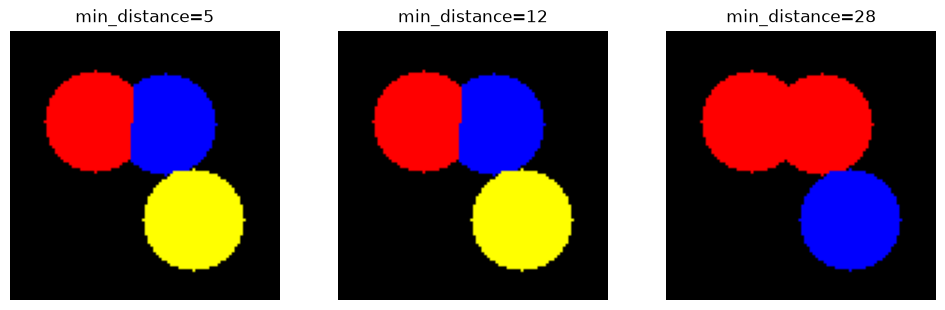

 min_distance  objects  TP  FP  FN  precision  recall  object_F1  matched_mean_IoU    PQ
            5        3   3   0   0        1.0   1.000        1.0             0.989 0.989
           12        3   3   0   0        1.0   1.000        1.0             0.989 0.989
           28        2   2   0   1        1.0   0.667        0.8             0.749 0.599


In [7]:
rows = []
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, spacing in zip(axes, [5, 12, 28]):
    pred, _ = watershed_instances(observed_foreground, min_distance=spacing)
    report, _ = instance_metrics(true_instances, pred)
    rows.append({'min_distance': spacing, 'objects': len(np.unique(pred))-1, **report})
    ax.imshow(label2rgb(pred, bg_label=0)); ax.set_title(f'min_distance={spacing}'); ax.axis('off')
plt.show()
print(pd.DataFrame(rows).round(3).to_string(index=False))


## Step 6 — Combine semantic and instance labels: a panoptic map

**Things** are countable objects (our disks); **stuff** is a region category (our background).
Each pixel gets both a semantic class and an instance/segment identity. Here semantic class 1
is background stuff; class 2 is a disk thing. Stuff uses instance ID 0; disks use positive IDs.
We pack them as `semantic * 1000 + instance`. This is our local teaching format, not COCO's file format.

Panoptic Quality for one class is
\(PQ=\sum_{(p,g)\in TP}IoU(p,g)/(TP+0.5FP+0.5FN)\).
When TP>0, it factors into matched-mask quality SQ and recognition quality RQ.
We match only within a semantic class and then average class PQ values equally.
Official evaluation additionally defines void/crowd handling, dataset aggregation, and class inclusion.


Segment IDs: [1000, 2001, 2002, 2003]
 segment_id  semantic_class  instance_id  area
       1000               1            0  6382
       2001               2            1   926
       2002               2            2   897
       2003               2            3  1011


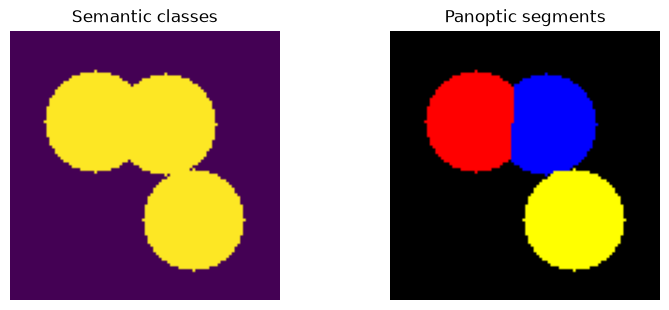

In [8]:
def pack_panoptic(instance_map):
    if instance_map.min() < 0 or instance_map.max() >= 1000:
        raise ValueError('This teaching encoding requires instance IDs in [0, 999].')
    semantic_map = np.where(instance_map > 0, 2, 1).astype(np.int32)
    packed = semantic_map*1000 + instance_map
    return semantic_map, packed

true_semantic, true_panoptic = pack_panoptic(true_instances)
pred_semantic, pred_panoptic = pack_panoptic(predicted_instances)
assert np.array_equal(pred_panoptic//1000, pred_semantic)
assert np.array_equal(pred_panoptic%1000, predicted_instances)
print('Segment IDs:', np.unique(pred_panoptic).tolist())
segments = [{'segment_id': int(s), 'semantic_class': int(s//1000),
             'instance_id': int(s%1000), 'area': int((pred_panoptic == s).sum())}
            for s in np.unique(pred_panoptic)]
print(pd.DataFrame(segments).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].imshow(pred_semantic, cmap='viridis', vmin=1, vmax=2); axes[0].set_title('Semantic classes')
axes[1].imshow(label2rgb(pred_panoptic, bg_label=1000)); axes[1].set_title('Panoptic segments')
for ax in axes: ax.axis('off')
plt.show()


In [9]:
# Same-class matching: treat all pixels of the stuff class as one segment.
class_rows = []
for class_id, name in [(1, 'background stuff'), (2, 'disk things')]:
    if class_id == 1:
        truth_for_class = (true_semantic == class_id).astype(np.int32)
        pred_for_class = (pred_semantic == class_id).astype(np.int32)
    else:
        truth_for_class = np.where(true_semantic == class_id, true_instances, 0)
        pred_for_class = np.where(pred_semantic == class_id, predicted_instances, 0)
    report, _ = instance_metrics(truth_for_class, pred_for_class, threshold=0.5)
    class_rows.append({'class': name, **report})
panoptic_report = pd.DataFrame(class_rows)
print(panoptic_report.round(4).to_string(index=False))
print('Toy class-mean PQ:', round(panoptic_report.PQ.mean(), 4))
print('No void/crowd regions in this synthetic scene; this is not a benchmark evaluator.')


           class  TP  FP  FN  precision  recall  object_F1  matched_mean_IoU     PQ
background stuff   1   0   0        1.0     1.0        1.0            1.0000 1.0000
     disk things   3   0   0        1.0     1.0        1.0            0.9892 0.9892
Toy class-mean PQ: 0.9946
No void/crowd regions in this synthetic scene; this is not a benchmark evaluator.


## Step 7 — Give point prompts to a classical algorithm

A prompt supplies information about the desired mask. We place positive foreground and
negative/background point labels on a small image. In random walker, label 0 means unknown,
1 means background seed, and 2 means foreground seed. These positive integers are categories;
a negative numeric label has a different API meaning and is not a negative prompt.

The algorithm propagates seed labels using image intensity differences. `beta` controls
sensitivity to those differences. The brute-force linear solver is convenient for this 64×64
example; large images require more suitable solvers and memory planning. This is a graph-based
method with no learned image representation.


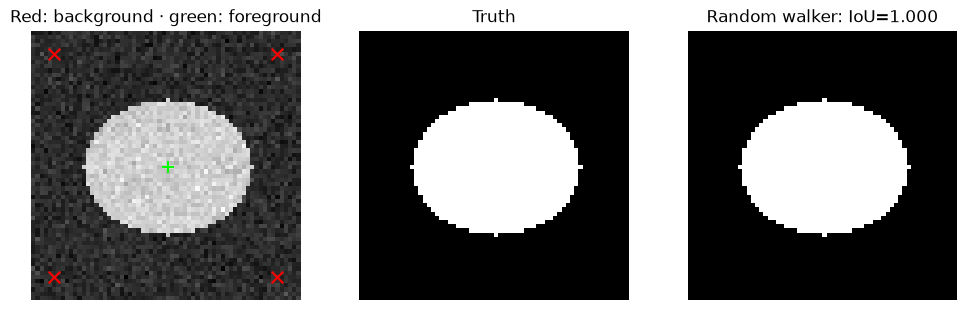

In [10]:
rr, cc = np.mgrid[:64, :64]
prompt_truth = ((rr-32)/16)**2 + ((cc-32)/20)**2 <= 1
prompt_image = np.clip(0.2+0.55*prompt_truth+
                       np.random.default_rng(8).normal(0, 0.045, (64, 64)), 0, 1)
prompt_seeds = np.zeros((64, 64), dtype=np.int32)
background_points = [(5, 5), (5, 58), (58, 5), (58, 58)]
foreground_points = [(32, 32)]
for row, col in background_points: prompt_seeds[row, col] = 1
for row, col in foreground_points: prompt_seeds[row, col] = 2
prompted_labels = random_walker(prompt_image, prompt_seeds, beta=90, mode='bf', channel_axis=None)
prompted_mask = prompted_labels == 2

def mask_iou(a, b):
    union = np.count_nonzero(a | b)
    return np.count_nonzero(a & b)/union if union else 1.0

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].imshow(prompt_image, cmap='gray')
for points, color, marker in [(background_points, 'red', 'x'), (foreground_points, 'lime', '+')]:
    rows, cols = np.array(points).T
    axes[0].scatter(cols, rows, c=color, marker=marker, s=70)
axes[0].set_title('Red: background · green: foreground')
axes[1].imshow(prompt_truth, cmap='gray'); axes[1].set_title('Truth')
axes[2].imshow(prompted_mask, cmap='gray'); axes[2].set_title(f'Random walker: IoU={mask_iou(prompt_truth, prompted_mask):.3f}')
for ax in axes: ax.axis('off')
plt.show()


## Step 8 — Prompt placement is part of the experiment

Move a foreground prompt into the background and observe the result. Seed constraints are
treated as known labels, so an incorrect prompt can force a wrong answer even with good
image contrast. For a fair comparison of promptable systems, define how prompts are chosen,
how many corrective clicks are allowed, and when the interaction stops.

Ground-truth-aware prompt placement, used here for teaching, is not an automatic deployment pipeline.


Correct center prompt IoU: 1.000
Misplaced foreground prompt IoU: 0.000


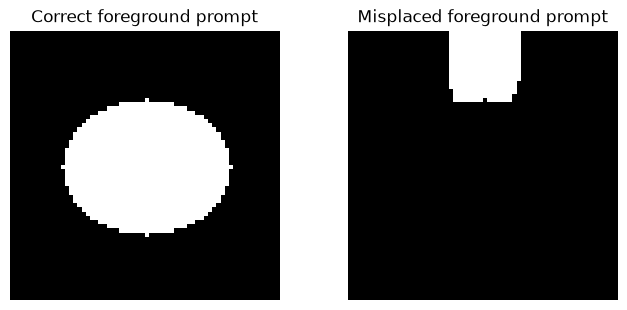

In [11]:
wrong_seeds = prompt_seeds.copy()
wrong_seeds[32, 32] = 0
wrong_seeds[8, 32] = 2  # intentionally incorrect foreground prompt
wrong_mask = random_walker(prompt_image, wrong_seeds, beta=90,
                           mode='bf', channel_axis=None) == 2
print(f'Correct center prompt IoU: {mask_iou(prompt_truth, prompted_mask):.3f}')
print(f'Misplaced foreground prompt IoU: {mask_iou(prompt_truth, wrong_mask):.3f}')
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
axes[0].imshow(prompted_mask, cmap='gray'); axes[0].set_title('Correct foreground prompt')
axes[1].imshow(wrong_mask, cmap='gray'); axes[1].set_title('Misplaced foreground prompt')
for ax in axes: ax.axis('off')
plt.show()


## Bridge to learned instance and promptable systems

| Method | Main input beyond the image | Output idea | What to investigate next |
|---|---|---|---|
| Watershed | Foreground mask and markers | Non-overlapping region IDs | Marker quality and touching-object errors |
| Random walker | Labeled seed pixels | Dense labels propagated from seeds | Prompt budget and contrast sensitivity |
| Mask R-CNN | Trained weights; labels during training | Detected objects, class scores, boxes, and masks | Detection confidence, overlap handling, class-aware AP |
| SAM | Pretrained weights and prompts such as points/boxes | Prompt-conditioned masks | Ambiguous masks, prompt protocol, domain suitability |
| Panoptic system | A model and semantic category definitions | A class and segment identity for every pixel | Thing/stuff reconciliation and official PQ evaluation |

A foundation model has learned from a large pretraining dataset. Our random walker has not.
A mask generator also does not automatically assign your dataset's semantic categories or
resolve all overlapping proposals into a panoptic map. Model-specific work needs its own
dependencies, weights, device budget, and data evaluation; no external model is downloaded here.

Follow the [official SAM repository](https://github.com/facebookresearch/segment-anything) for its
original model and prompt examples, and the [Torchvision Mask R-CNN documentation](https://docs.pytorch.org/vision/stable/models/mask_rcnn.html)
for available model interfaces. These links are optional extensions, not prerequisites to run this lesson.


## Your experiments

**Exercise 1 — Rename every object.** Change predicted IDs by an arbitrary permutation.
Prove that instance precision and recall remain unchanged.

<details><summary>Worked solution</summary>

```python
permuted = np.zeros_like(predicted_instances)
ids = np.unique(predicted_instances)
ids = ids[ids > 0]
for old, new in zip(ids, ids[::-1] + 100):
    permuted[predicted_instances == old] = new
changed, _ = instance_metrics(true_instances, permuted)
assert changed['precision'] == instance_report['precision']
assert changed['recall'] == instance_report['recall']
```

The IoU matrix columns are permuted, but geometry and eligible one-to-one matches are unchanged.

</details>

**Exercise 2 — Raise the IoU threshold.** Compare thresholds 0.5, 0.75, and 0.9. Explain why
object recall may decrease although the predicted mask did not change. This is a fixed-threshold
score sweep; do not call its average COCO AP.

<details><summary>Worked solution</summary>

```python
print(pd.DataFrame([{'threshold': t,
    **instance_metrics(true_instances, predicted_instances, threshold=t)[0]}
    for t in [0.5, 0.75, 0.9]]))
```

Stricter thresholds reject less accurate geometric matches, turning one previous TP into an
FP and an FN. Results may remain unchanged if all matched masks already have very high IoU.

</details>

**Exercise 3 — Repair a prompt.** Keep the misplaced foreground prompt and add a correct
foreground prompt at the center. Then instead remove the wrong prompt. Compare the two outcomes.

<details><summary>Worked solution</summary>

```python
added = wrong_seeds.copy(); added[32, 32] = 2
removed = added.copy(); removed[8, 32] = 0
for name, seeds in [('added only', added), ('removed wrong seed', removed)]:
    result = random_walker(prompt_image, seeds, beta=90, mode='bf', channel_axis=None) == 2
    print(name, mask_iou(prompt_truth, result))
```

Adding a correct seed does not erase the contradictory hard constraint. Removing the wrong
seed restores a consistent set of labels. Always inspect the prompts as well as the output.

</details>


In [12]:
# Your workspace: record counts as well as overlap.
trial_rows = [{'IoU_threshold': t, **instance_metrics(true_instances, predicted_instances, t)[0]}
              for t in [0.5, 0.75, 0.9]]
print(pd.DataFrame(trial_rows).round(3).to_string(index=False))


 IoU_threshold  TP  FP  FN  precision  recall  object_F1  matched_mean_IoU    PQ
          0.50   3   0   0        1.0     1.0        1.0             0.989 0.989
          0.75   3   0   0        1.0     1.0        1.0             0.989 0.989
          0.90   3   0   0        1.0     1.0        1.0             0.989 0.989


## Common mistakes and completion checklist

- **Comparing ID numbers directly:** match masks by geometry and semantic class.
- **Counting a merge as several true positives:** each prediction gets at most one match.
- **Reporting foreground IoU as instance quality:** splits/merges can preserve the foreground union.
- **Calling object F1 AP:** AP needs confidence-ranked detections and a complete benchmark protocol.
- **Calling a packed integer image a panoptic model:** encoding organizes outputs; it does not learn them.
- **Using label -1 as a background prompt in random walker:** positive labels identify seed classes;
  check the API's separate inactive-pixel meaning for negative labels.

- [ ] Explain why connected components merges touching disks.
- [ ] Match instances without relying on their numeric IDs.
- [ ] Count TP/FP/FN for split and merged masks and state the IoU threshold.
- [ ] Encode and decode semantic/instance IDs and compute the toy classwise PQ.
- [ ] Explain the difference between classical seed propagation and a pretrained promptable model.
- [ ] State what this toy evaluation omits before adapting it to real data.

**Continue:** use these evaluation ideas in the capstone, with a declared task and independent data splits.

**Primary references:** [scikit-image segmentation API (watershed and random walker)](https://scikit-image.org/docs/stable/api/skimage.segmentation.html),
[SciPy assignment API](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linear_sum_assignment.html),
[official COCO panoptic evaluation repository](https://github.com/cocodataset/panopticapi),
[official SAM repository](https://github.com/facebookresearch/segment-anything),
[Torchvision Mask R-CNN](https://docs.pytorch.org/vision/stable/models/mask_rcnn.html).
